In [32]:
!unzip archive.zip

Archive:  archive.zip
replace processed_repetitions/2d_joints/Ex1/PM_001_rep10_label0.npy? [y]es, [n]o, [A]ll, [N]one, [r]ename: y
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep10_label0.npy  
replace processed_repetitions/2d_joints/Ex1/PM_001_rep1_label1.npy? [y]es, [n]o, [A]ll, [N]one, [r]ename: A
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep1_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep2_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep3_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep4_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep5_label1.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep6_label0.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep7_label0.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep8_label0.npy  
  inflating: processed_repetitions/2d_joints/Ex1/PM_001_rep9_label0.npy  
  inflating: process

In [33]:
path = '/content/processed_repetitions/2d_joints/Ex2'

In [34]:
!pip install optuna

In [35]:
import copy
import os
import re
import numpy as np
import optuna
import torch
import torch.nn as nn
import torch.nn.functional as TF
import matplotlib.pyplot as plt
from IPython.display import Image as IPImage, display
from collections import defaultdict
from dataclasses import dataclass

from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import NearestNeighbors
from sklearn.metrics import (matthews_corrcoef, roc_auc_score, roc_curve,
                             confusion_matrix, pairwise_distances)
from sklearn.model_selection import train_test_split
from scipy.signal import savgol_filter

In [36]:
DEVICE   = "cuda" if torch.cuda.is_available() else "cpu"
SEED     = 42
N_TRIALS = 40
N_MASKS  = 8
SAVE_PATH = "/content/kaggle"

torch.backends.cudnn.deterministic = True

In [37]:
def set_seed(s):
    np.random.seed(s)
    torch.manual_seed(s)
    torch.cuda.manual_seed_all(s)

set_seed(SEED)

In [38]:
FNAME_RE = re.compile(r"PM_(\w+?)_rep(\d+)_label(\d)\.npy")

def build_records(exercise_dir):
    records = []
    for fname in os.listdir(exercise_dir):
        m = FNAME_RE.match(fname)
        if not m:
            continue
        person, rep, label = m.group(1), int(m.group(2)), int(m.group(3))
        records.append({"path": os.path.join(exercise_dir, fname),
                        "person_id": person, "rep": rep, "label": label})
    return records

In [39]:
# person-disjoint deterministic split (seed 42, stratified by flawed share)
def subject_split(records, test_size=0.2, seed=42):
    """Person-disjoint train/test split, deterministic, percentage-based."""
    persons = sorted({r["person_id"] for r in records})
    per_person = defaultdict(list)
    for r in records:
        per_person[r["person_id"]].append(r["label"])

    flawed_share = np.array([1.0 - (sum(per_person[p]) / len(per_person[p])) for p in persons])
    strata = np.digitize(flawed_share, [0.001, 0.25, 0.75, 0.999])
    persons_arr = np.array(persons)

    try:
        train_persons, test_persons = train_test_split(
            persons_arr, test_size=test_size, random_state=seed, stratify=strata, shuffle=True)
    except ValueError:
        train_persons, test_persons = train_test_split(
            persons_arr, test_size=test_size, random_state=seed, shuffle=True)

    train_set = set(train_persons.tolist())
    train = [r for r in records if r["person_id"] in train_set]
    test  = [r for r in records if r["person_id"] not in train_set]

    print(f"[split seed={seed} test_size={test_size}] "
          f"train={len(train_set)} persons, test={len(test_persons)} persons | "
          f"train reps P={sum(r['label'] for r in train)}, test reps P={sum(r['label'] for r in test)}")
    return train, test

In [40]:
records = build_records(path)
train, test = subject_split(records, 0.2, 42)

[split seed=42 test_size=0.2] train=8 persons, test=3 persons | train reps P=44, test reps P=27


In [41]:
JN = {
    "Hips": 0, "Spine": 1, "Spine1": 2, "Neck": 3, "Head": 4, "Head_end": 5,
    "LeftShoulder": 6, "LeftArm": 7, "LeftForeArm": 8, "LeftHand": 9, "LeftHand_end": 10,
    "RightShoulder": 11, "RightArm": 12, "RightForeArm": 13, "RightHand": 14, "RightHand_end": 15,
    "LeftUpLeg": 16, "LeftLeg": 17, "LeftFoot": 18, "LeftToeBase": 19, "LeftToeBase_end": 20,
    "RightUpLeg": 21, "RightLeg": 22, "RightFoot": 23, "RightToeBase": 24, "RightToeBase_end": 25,
}
g = lambda s, name: s[:, JN[name], :]

In [42]:
# bone sets (upper body = feature mask; full body = ghost drawing)
UPPER_BONES = [(0, 1), (1, 2), (2, 3), (3, 4),
               (6, 7), (7, 8), (8, 9),
               (11, 12), (12, 13), (13, 14),
               (0, 6), (0, 11), (1, 6), (1, 11)]

LEG_BONES = [(0, 16), (0, 21),
             (16, 17), (17, 18), (18, 19), (19, 20),
             (21, 22), (22, 23), (23, 24), (24, 25)]

HEAD_TIP  = [(4, 5), (9, 10), (14, 15)]
FULL_BONES = UPPER_BONES + LEG_BONES + HEAD_TIP

# X2d column layout (56 cols): ANG 0-8, DANG 8-16, BONE 16-44, POS 44-56
ANG  = slice(0, 8);   DANG = slice(8, 16)
BONE = slice(16, 44); POS  = slice(44, 56)
BLOCKS = {"ang": ANG, "dang": DANG, "bone": BONE, "pos": POS, "full": slice(0, 56)}

In [43]:
@dataclass
class ExConfig:
    n_frames: int = 90
    sgf_win: int = 11
    sgf_poly: int = 2

    use_angles: bool = True
    use_bone_vectors: bool = True
    use_arm_positions: bool = True
    use_angular_velocity: bool = True
    use_angular_accel: bool = False
    use_joint_speed: bool = False

    use_mirror_canonicalization: bool = True
    torso_eps: float = 1e-6

    angle_defs: tuple = (
        ("Neck", "LeftShoulder", "LeftArm"),
        ("Neck", "RightShoulder", "RightArm"),
        ("LeftShoulder", "LeftArm", "LeftForeArm"),
        ("RightShoulder", "RightArm", "RightForeArm"),
        ("LeftArm", "LeftForeArm", "LeftHand"),
        ("RightArm", "RightForeArm", "RightHand"),
        ("Hips", "Spine1", "Neck"),
    )
    arm_position_joints: tuple = ("LeftArm", "LeftForeArm", "LeftHand",
                                  "RightArm", "RightForeArm", "RightHand")

CFG = ExConfig()

### normalizers (canonical -> spatial -> smooth -> resample)

In [44]:
def mirror_x(seq):
    """Mirror about the pelvis vertical axis. seq: (T,26,2)."""
    pelvis_x = seq[:, JN["Hips"], 0:1]
    out = seq.copy()
    out[:, :, 0] = 2.0 * pelvis_x - out[:, :, 0]
    return out

def canonicalize(seq, is_mirror_rep, cfg=CFG):
    if cfg.use_mirror_canonicalization and is_mirror_rep:
        return mirror_x(seq)
    return seq.copy()

In [45]:
def spatial_normalize(seq, cfg=CFG):
    out = seq.copy() - seq[:, JN["Hips"], :][:, None, :]
    a = seq[:, JN["Hips"], :]
    b = seq[:, JN["Spine"], :]
    tl = np.linalg.norm(b - a, axis=-1)
    tl = np.maximum(tl, cfg.torso_eps)
    return out / tl[:, None, None]

In [46]:
def smooth(seq, cfg=CFG):
    T = seq.shape[0]
    win = min(cfg.sgf_win if cfg.sgf_win % 2 == 1 else cfg.sgf_win + 1, (T // 2) * 2 + 1)
    if win < 5:
        return seq
    return np.stack([savgol_filter(seq[:, j, :], win, cfg.sgf_poly, axis=0)
                     for j in range(seq.shape[1])], axis=1)

In [47]:
def resample(seq, n=None):
    n = CFG.n_frames if n is None else n
    T = seq.shape[0]
    if T == n:
        return seq.copy()
    xs = np.arange(T)
    xd = np.linspace(0, T - 1, n)
    return np.stack([np.stack([np.interp(xd, xs, seq[:, j, c]) for c in range(2)],
                               axis=-1) for j in range(seq.shape[1])], axis=1)

### feature extractors

In [48]:
def angle_abc(a, b, c):
    ab, bc = a - b, c - b
    denom = (np.linalg.norm(ab, axis=-1) * np.linalg.norm(bc, axis=-1)) + 1e-9
    return np.degrees(np.arccos(np.clip(np.sum(ab * bc, axis=-1) / denom, -1, 1)))

def angle_channels(seq, cfg=CFG):
    feats, names = [], []
    for (p, v, d) in cfg.angle_defs:
        feats.append(angle_abc(g(seq, p), g(seq, v), g(seq, d)))
        names.append(f"ang_{v}")
    sh = g(seq, "RightShoulder") - g(seq, "LeftShoulder")
    feats.append(np.degrees(np.arctan2(sh[:, 1], sh[:, 0])))
    names.append("ang_shoulder_tilt")
    return np.stack(feats, axis=1), names

def bone_channels(seq, cfg=CFG):
    feats, names = [], []
    for (s, e) in UPPER_BONES:
        v = seq[:, e, :] - seq[:, s, :]
        feats.append(v[:, 0]); names.append(f"bone_{s}_{e}_x")
        feats.append(v[:, 1]); names.append(f"bone_{s}_{e}_y")
    return np.stack(feats, axis=1), names

def arm_position_channels(seq, cfg=CFG):
    feats, names = [], []
    for name in cfg.arm_position_joints:
        p = g(seq, name)
        feats.append(p[:, 0]); names.append(f"pos_{name}_x")
        feats.append(p[:, 1]); names.append(f"pos_{name}_y")
    return np.stack(feats, axis=1), names

def kinematic_channels(angles, seq, cfg=CFG):
    feats, names = [], []
    if cfg.use_angular_velocity:
        feats.append(np.gradient(angles, axis=0))
        names += [f"dang_{i}" for i in range(angles.shape[1])]
    if cfg.use_angular_accel:
        feats.append(np.gradient(angles, axis=0, edge_order=2)
                     if angles.shape[0] > 2 else np.zeros_like(angles))
        names += [f"d2ang_{i}" for i in range(angles.shape[1])]
    if cfg.use_joint_speed:
        v = np.gradient(seq, axis=0)
        speeds = np.linalg.norm(v, axis=-1)
        sel = [JN[n] for n in cfg.arm_position_joints]
        feats.append(speeds[:, sel])
        names += [f"speed_{cfg.arm_position_joints[i]}" for i in range(len(sel))]
    if not feats:
        return np.zeros((angles.shape[0], 0)), []
    return np.concatenate(feats, axis=1), names

### per-rep pipeline

In [49]:
def build_rep(coord, is_mirror_rep=False, cfg=CFG, return_template=True):
    x = np.asarray(coord, dtype=np.float64)
    x = canonicalize(x, is_mirror_rep, cfg)
    x = spatial_normalize(x, cfg)
    x_s = smooth(x, cfg)
    x_r = resample(x_s, cfg.n_frames)

    blocks, blk_names = [], []
    if cfg.use_angles:
        a, n = angle_channels(x_r, cfg)
        blocks.append(a); blk_names += n
        kin, kn = kinematic_channels(a, x_r, cfg)
        blocks.append(kin); blk_names += kn
    if cfg.use_bone_vectors:
        b, n = bone_channels(x_r, cfg)
        blocks.append(b); blk_names += n
    if cfg.use_arm_positions:
        p, n = arm_position_channels(x_r, cfg)
        blocks.append(p); blk_names += n
    if not blk_names:
        raise ValueError("no feature channels enabled in ExConfig")

    X = np.concatenate(blocks, axis=1)
    if not np.isfinite(X).all():
        raise ValueError("non-finite features produced (bad rep?)")

    out = {"X": X.astype(np.float32), "names": blk_names}
    if return_template:
        out["template"] = resample(x, cfg.n_frames).astype(np.float32)
    return out

In [50]:
class FeatureScaler:
    """Standardization fitted on TRAIN persons ONLY."""
    def __init__(self):
        self.mean_ = None
        self.std_ = None

    def fit(self, X):
        X = np.asarray(X, dtype=np.float64)
        self.mean_ = X.mean(axis=0)
        std = X.std(axis=0)
        std[std < 1e-8] = 1.0
        self.std_ = std
        return self

    def transform(self, X):
        return ((np.asarray(X, dtype=np.float64) - self.mean_) / self.std_).astype(np.float32)

    def fit_transform(self, X):
        return self.fit(X).transform(X)

In [51]:
# feature cache (built ONCE, not inside the Optuna loop)
def build_feature_cache(records, cfg=CFG):
    out = []
    for r in sorted(records, key=lambda r: (r["person_id"], r["rep"])):
        arr = np.load(r["path"])
        if arr.ndim != 3 or arr.shape[0] < 10:
            continue
        b = build_rep(arr, r.get("is_mirror_rep", False), cfg)
        rec = dict(r)
        rec["X2d"]      = b["X"]
        rec["template"] = b["template"]
        out.append(rec)
    return out

feat_train = build_feature_cache(train)
feat_test  = build_feature_cache(test)
print(f"cached features: train={len(feat_train)} reps, test={len(feat_test)} reps "
      f"| per-rep shape={feat_train[0]['X2d'].shape}")

cached features: train=115 reps, test=47 reps | per-rep shape=(90, 56)


### sequence standardization + spec base class

In [52]:
def std_rows(rows, scaler):
    """Standardize each cached rep (90,56) with the train-fitted scaler -> (N,90,56)."""
    return np.stack([scaler.transform(r["X2d"]) for r in rows]).astype(np.float32)

def _is_sup(spec):
    return bool(getattr(spec, "supervised", False))

class ArchSpec:
    """Per-architecture contract. Each arch = one subclass, nothing else to touch."""
    name = "arch"
    supervised = False
    def search_space(self, trial): raise NotImplementedError   # Optuna search space
    def train(self, X, y, p, seed): raise NotImplementedError  # X = packed
    def score(self, model, X, p): raise NotImplementedError    # (N,) higher = more flawed
    def pack(self, std_list, rows=None): raise NotImplementedError
    def embed(self, model, rows): raise NotImplementedError    # (N,latent) for the bank

def tpl_stack(rows):
    return np.stack([r["template"] for r in rows])            # (N,90,26,2), already normalized + resampled

def jn_take(names):
    """Only joints that exist in JN (defensive against name drift)."""
    return [JN[n] for n in names if n in JN]

### metrics (positive class = label 1 = PERFECT) + confusion + ROC

In [53]:
def compute_all_metrics(y_true, y_pred, y_proba, beta=2.0):
    y_true, y_pred = np.asarray(y_true), np.asarray(y_pred)
    tp = int(np.sum((y_true == 1) & (y_pred == 1)))
    tn = int(np.sum((y_true == 0) & (y_pred == 0)))
    fp = int(np.sum((y_true == 0) & (y_pred == 1)))
    fn = int(np.sum((y_true == 1) & (y_pred == 0)))
    prec = tp / max(tp + fp, 1); rec = tp / max(tp + fn, 1)
    spec = tn / max(tn + fp, 1); acc = (tp + tn) / max(tp + tn + fp + fn, 1)
    f1 = 2 * prec * rec / max(prec + rec, 1e-6)
    fb = (1 + beta ** 2) * prec * rec / max(beta ** 2 * prec + rec, 1e-6)
    mcc = float(matthews_corrcoef(y_true, y_pred)) if len(np.unique(y_true)) >= 2 else 0.0
    auroc = float(roc_auc_score(y_true, y_proba)) if len(np.unique(y_true)) >= 2 else 0.0
    return {"accuracy": acc, "balanced_acc": (rec + spec) / 2.0,
            "precision": prec, "recall": rec, "sensitivity": rec,
            "specificity": spec, "f1": f1, f"f{int(beta)}": fb,
            "mcc": mcc, "auroc": auroc,
            "tp": tp, "tn": tn, "fp": fp, "fn": fn}

def print_confusion_matrix(y_true, y_pred, exercise_id):
    cm = confusion_matrix(y_true, y_pred, labels=[1, 0])
    print(f"\n  [{exercise_id}] Confusion Matrix:")
    print("                  Predicted PASS  Predicted FAIL")
    if cm.shape == (2, 2):
        tp, fn = cm[0, 0], cm[0, 1]
        fp, tn = cm[1, 0], cm[1, 1]
        print(f"  True PERFECT:  {tp:4d} ({tp / max(tp + fn, 1) * 100:5.1f}%)    "
              f"{fn:4d} ({fn / max(tp + fn, 1) * 100:5.1f}%)")
        print(f"  True FLAWED:   {fp:4d} ({fp / max(tn + fp, 1) * 100:5.1f}%)    "
              f"{tn:4d} ({tn / max(tn + fp, 1) * 100:5.1f}%)")
    else:
        print(f"  {cm}")

def plot_roc_curve(y_true, y_proba, exercise_id, save_path=SAVE_PATH):
    if len(np.unique(y_true)) < 2:
        return None
    fpr, tpr, _ = roc_curve(y_true, y_proba)
    auroc = roc_auc_score(y_true, y_proba)
    fig, ax = plt.subplots(figsize=(5, 4))
    ax.plot(fpr, tpr, color="steelblue", lw=2.5, label=f"ROC (AUROC={auroc:.3f})")
    ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random")
    ax.set_xlabel("FPR (1-Specificity)", fontsize=9)
    ax.set_ylabel("TPR (Sensitivity)", fontsize=9)
    ax.set_title(f"{exercise_id} — ROC Curve", fontsize=10)
    ax.legend(fontsize=8); ax.grid(True, ls=":", alpha=0.4)
    fpath = os.path.join(save_path, f"{exercise_id}_roc.png")
    plt.savefig(fpath, dpi=100, bbox_inches="tight"); plt.close()
    display(IPImage(fpath))
    return fpath

### generic Optuna tuner + finalize + OOF-Platt (work for ANY spec)

In [54]:
def run_optuna_for(spec, rows, n_trials=N_TRIALS):
    persons = sorted({r["person_id"] for r in rows})
    rng = np.random.RandomState(SEED)
    val_p = set(persons[i] for i in rng.permutation(len(persons))[:max(2, len(persons) // 5)])
    tr_r = [r for r in rows if r["person_id"] not in val_p]
    va_r = [r for r in rows if r["person_id"] in val_p]
    print(f"  optuna inner split: train reps={len(tr_r)} val reps={len(va_r)} "
          f"(person-disjoint: {len({r['person_id'] for r in tr_r})}/{len(val_p)} persons)")

    def objective(trial):
        p = spec.search_space(trial)
        sc = FeatureScaler().fit(np.concatenate([r["X2d"] for r in tr_r if r["label"] == 1], 0))
        # unsupervised specs train on CORRECT reps only (same filter as finalize/platt —
        # this was the inconsistency that corrupted the AE tuning before)
        tr_fit = tr_r if _is_sup(spec) else [f for f in tr_r if f["label"] == 1]
        Xt = spec.pack(std_rows(tr_fit, sc), tr_fit)
        vt = spec.pack(std_rows(va_r, sc), va_r)
        y_tr = np.array([r["label"] for r in tr_fit])
        model = (spec.train(Xt, y_tr, p, SEED) if _is_sup(spec)
                 else spec.train(Xt, None, p, SEED))
        s_tr = spec.score(model, Xt, p); s_va = spec.score(model, vt, p)
        y_va = np.array([r["label"] for r in va_r])
        thr = np.percentile(s_tr[y_tr == 1], p["q"]) if _is_sup(spec) \
              else np.percentile(s_tr, p["q"])
        mcc = matthews_corrcoef(y_va, (s_va <= thr).astype(int))
        auroc = roc_auc_score(y_va, -s_va)
        return mcc + auroc

    study = optuna.create_study(direction="maximize",
              sampler=optuna.samplers.TPESampler(seed=SEED),
              pruner=optuna.pruners.MedianPruner())
    study.optimize(objective, n_trials=n_trials, show_progress_bar=True)
    return study

def finalize_for(spec, study, feats_train, feats_test):
    p = dict(study.best_params)
    Xc_rows = [f for f in feats_train if f["label"] == 1]
    scaler  = FeatureScaler().fit(np.concatenate([r["X2d"] for r in Xc_rows], 0))
    set_seed(SEED)
    tr_rows = feats_train if _is_sup(spec) else Xc_rows
    Xt = spec.pack(std_rows(tr_rows, scaler), tr_rows)
    y_tr = np.array([f["label"] for f in tr_rows])
    model = (spec.train(Xt, y_tr, p, SEED) if _is_sup(spec)
             else spec.train(Xt, None, p, SEED))
    Xt_c = spec.pack(std_rows(Xc_rows, scaler), Xc_rows)
    errs_c = spec.score(model, Xt_c, p)
    thr = float(np.percentile(errs_c, p["q"]))
    print(f"provisional score threshold: {thr:.6f}")

    Xt_rows = list(feats_test)
    st = spec.score(model, spec.pack(std_rows(Xt_rows, scaler), Xt_rows), p)
    yt = np.array([r["label"] for r in Xt_rows])

    m = compute_all_metrics(yt, (st <= thr).astype(int), -st)
    print_confusion_matrix(yt, (st <= thr).astype(int), spec.name)
    plot_roc_curve(yt, -st, spec.name)
    return dict(spec=spec, params=p, scaler=scaler, model=model, threshold=thr,
                metrics=m, scores=st, y=yt, rows=Xt_rows, study=study)

def platt_fit_oof_for(spec, study, feat_train, n_folds=2):
    """Person-disjoint folds; OOF Platt fitted on log-scores, target = FLAWED."""
    p = dict(study.best_params)
    persons = sorted({f["person_id"] for f in feat_train})
    assert len(persons) >= 2 * n_folds, "too few persons for OOF-Platt folds"
    rng = np.random.default_rng(SEED)
    perm = rng.permutation(len(persons))
    folds = [set(np.array(persons)[c].tolist()) for c in np.array_split(perm, n_folds)]

    pl, ys = [], []
    for ps in folds:
        tr_r = [f for f in feat_train if f["person_id"] not in ps]
        te_r = [f for f in feat_train if f["person_id"] in ps]
        sc = FeatureScaler().fit(np.concatenate(
            [r["X2d"] for r in tr_r if r["label"] == 1], 0))
        tr_fit = tr_r if _is_sup(spec) else [f for f in tr_r if f["label"] == 1]
        Xt = spec.pack(std_rows(tr_fit, sc), tr_fit)
        y_tr = np.array([r["label"] for r in tr_fit])
        model = (spec.train(Xt, y_tr, p, SEED) if _is_sup(spec)
                 else spec.train(Xt, None, p, SEED))
        s = spec.score(model, spec.pack(std_rows(te_r, sc), te_r), p)
        pl += [np.log(np.clip(s, 1e-4, None))]
        ys += [f["label"] for f in te_r]
    pl, ys = np.concatenate(pl), np.array(ys, dtype=float)

    ys_f = 1.0 - ys                              # 1 = FLAWED (model score unit)
    lr2 = LogisticRegression(max_iter=1000).fit(pl.reshape(-1, 1), ys_f.astype(int))
    p_flawed = lr2.predict_proba(pl.reshape(-1, 1))[:, 1]
    auroc = roc_auc_score(ys_f, p_flawed)        # flawed-ranking AUROC
    slope = float(lr2.coef_[0][0])
    gate = "PASS" if (auroc > 0.5 and slope > 0) else "*** FAIL — do not ship verdicts ***"
    print(f"  Platt a={slope:.3f} b={lr2.intercept_[0]:.3f} | "
          f"OOF AUROC(flawed)={auroc:.3f} [{gate}] | "
          f"P(flawed): correct={p_flawed[ys_f == 0].mean():.3f} "
          f"flawed={p_flawed[ys_f == 1].mean():.3f}")
    return {"a": slope, "b": float(lr2.intercept_[0]), "oof_auroc": auroc}

def platt_p_flawed(platt, scores):
    z = platt["a"] * np.log(np.clip(scores, 1e-4, None)) + platt["b"]
    return 1.0 / (1.0 + np.exp(-z))

In [55]:
BUNDLES = {}             # registry: every run lands here; summary cell at the bottom

def run_experiment(spec, feat_train, feat_test, n_trials=N_TRIALS, n_folds=2, show_bank=True, ex_name=None):
    ex = ex_name or spec.name
    print(f"\n======== {ex} ========")
    study = run_optuna_for(spec, feat_train, n_trials)
    print("BEST params :", study.best_params)

    best  = finalize_for(spec, study, feat_train, feat_test)
    platt = platt_fit_oof_for(spec, study, feat_train, n_folds=n_folds)
    p_flawed = platt_p_flawed(platt, best["scores"])
    y_pred_platt = (p_flawed < 0.5).astype(int)          # PASS when P(flawed) < 0.5
    m = compute_all_metrics(best["y"], y_pred_platt, 1.0 - p_flawed)  # proba for PERFECT class
    print(f"\n  [{ex}] OOF-Platt calibrated test report")
    print({k: (round(v, 4) if isinstance(v, (int, float, np.floating)) else v) for k, v in m.items()})
    print_confusion_matrix(best["y"], y_pred_platt, f"{ex}-OOFPlatt")
    plot_roc_curve(best["y"], 1.0 - p_flawed, f"{ex}_platt")
    best.update(platt=platt, p_flawed=p_flawed, p_metrics=m)
    BUNDLES[ex] = best

    if show_bank:
        model = best["model"]
        bank = CorrectionBank([f for f in feat_train if f["label"] == 1],
                              embed_fn=lambda rows: spec.embed(model, rows))
        i = int(np.argmax(p_flawed))
        rec = best["rows"][i]
        print(f"worst test rep: {rec['person_id']} rep{rec['rep']} "
              f"label={rec['label']} p_flawed={p_flawed[i]:.3f}")
        corr = bank.correct(rec)
        bank_summary(corr)
        plot_ghost_overlay(rec, corr, prefix=ex)
    return best

### CorrectionBank + summary (embed_fn provided via spec closure)

In [56]:
JN_R = {v: k for k, v in JN.items()}

class CorrectionBank:
    def __init__(self, records, embed_fn):
        self.records = records
        self.embed_fn = embed_fn
        self.embs = embed_fn(records)
        self.by_person = {}
        for rec, e in zip(records, self.embs):
            self.by_person.setdefault(rec["person_id"], []).append((e, rec))

    def query(self, rec):
        q = self.embed_fn([rec])[0]
        pool = self.by_person.get(rec["person_id"]) or list(zip(self.embs, self.records))
        d = np.array([np.linalg.norm(q - e) for e, _ in pool])
        i = int(np.argmin(d))
        return pool[i][1], float(d[i])

    def correct(self, rec):
        ref, dist = self.query(rec)
        delta = ref["template"] - rec["template"]
        return {"ref": ref, "distance": dist, "delta": delta,
                "per_joint_disp": np.linalg.norm(delta, axis=-1).mean(0)}

def bank_summary(corr, top_k=4):
    """y grows DOWNWARD in the data: delta_y < 0 late in the rep -> 'raise it'."""
    top = np.argsort(-corr["per_joint_disp"])[:top_k]
    disp, delta = corr["per_joint_disp"], corr["delta"]
    F = delta.shape[0]
    imax = int(np.argmax(np.linalg.norm(delta, axis=-1)) // delta.shape[1])
    print(f"  reference distance (latent space): {corr['distance']:.4f}")
    print(f"  peak mismatch around frame {imax}/{F} "
          f"({'late' if imax > F / 2 else 'early' if imax < F / 4 else 'mid'} phase)")
    for j in top:
        print(f"   joint {j:>2} ({JN_R[j]:<13}) mean offset={disp[j]:.3f} torso-units")

### ghost overlay (full skeleton, shared window, y-down fixed)

In [57]:
def _draw_skel(ax, P, color, lw=1.2, label=None, ls="-"):
    ax.scatter(P[:, 0], P[:, 1], s=10, c=color, zorder=3, label=label)
    emphasized = set(UPPER_BONES)
    for s, e in FULL_BONES:
        if (s, e) in emphasized:
            ax.plot([P[s, 0], P[e, 0]], [P[s, 1], P[e, 1]], c=color, lw=lw, ls=ls, zorder=2)
        else:
            ax.plot([P[s, 0], P[e, 0]], [P[s, 1], P[e, 1]], c=color, lw=0.7, ls=ls, alpha=0.45, zorder=1)

def plot_ghost_overlay(rec, corr, sel=None, top_k=4, save_path=SAVE_PATH, prefix="Ex2"):
    rep, ref = rec["template"], corr["ref"]["template"]
    F = rep.shape[0]
    sel = sel or [0, F // 4, F // 2, 3 * F // 4, F - 1]
    top = np.argsort(-corr["per_joint_disp"])[:top_k]

    frames = np.concatenate([rep[sel], ref[sel]], axis=0)
    pad = 0.15
    x0, x1 = frames[:, :, 0].min(), frames[:, :, 0].max()
    y0, y1 = frames[:, :, 1].min(), frames[:, :, 1].max()
    xr, yr = (x1 - x0) or 1.0, (y1 - y0) or 1.0
    xlim, ylim = (x0 - pad * xr, x1 + pad * xr), (y0 - pad * yr, y1 + pad * yr)

    fig, axes = plt.subplots(1, len(sel), figsize=(3.1 * len(sel), 4.2))
    for ax, t in zip(np.atleast_1d(axes), sel):
        _draw_skel(ax, ref[t], "0.45", ls=":", label="ghost (correct ref)" if t == sel[0] else None)
        _draw_skel(ax, rep[t], "steelblue", label="performed rep" if t == sel[0] else None)
        for j in top:
            ax.annotate("", xy=ref[t, j], xytext=rep[t, j],
                        arrowprops=dict(arrowstyle="->", lw=1.4, color="crimson"))
        ax.set_xlim(*xlim)
        ax.set_ylim(ylim[1], ylim[0])     # y grows DOWNWARD in the data
        ax.set_aspect("equal")            # shared honest scale for all panels
        ax.set_title(f"frame {t}", fontsize=9); ax.axis("off")
    axes = np.atleast_1d(axes)
    axes[0].legend(fontsize=8, loc="lower left")
    fig.suptitle(f"{prefix} ghost overlay — {rec['person_id']} rep{rec['rep']} "
                 f"| latent dist={corr['distance']:.3f}", fontsize=10)
    fpath = os.path.join(save_path, f"{prefix}_ghost_{rec['person_id']}_rep{rec['rep']}.png")
    plt.savefig(fpath, dpi=110, bbox_inches="tight"); plt.close()
    display(IPImage(fpath))
    return fpath

## Masked AE

In [58]:
class _AE(nn.Module):
    def __init__(self, Din, p):
        super().__init__()
        dims = np.geomspace(p["width"], p["latent"], p["n_layers"])
        dims = np.maximum(np.round(dims).astype(int), 8); dims[0], dims[-1] = p["width"], p["latent"]
        act = {"relu": nn.ReLU, "gelu": nn.GELU}[p["act"]]
        enc, d = [], Din
        for h in dims:
            enc += [nn.Linear(d, h), act(), nn.Dropout(p["dropout"])]; d = h
        dec, d = [], p["latent"]
        for h in reversed(dims[:-1]):
            dec += [nn.Linear(d, h), act(), nn.Dropout(p["dropout"])]; d = h
        dec += [nn.Linear(d, Din)]
        self.encoder, self.decoder = nn.Sequential(*enc), nn.Sequential(*dec)
    def forward(self, x):
        return self.decoder(self.encoder(x))

In [59]:
class MaskedAnAESpec(ArchSpec):
    name = "Ex2-MaskedAnatAE"
    supervised = False

    JOINTS = ["Hips", "Spine", "Spine1", "Neck",
              "LeftShoulder", "LeftArm", "LeftForeArm", "LeftHand", "LeftHand_end",
              "RightShoulder", "RightArm", "RightForeArm", "RightHand", "RightHand_end"]

    def search_space(self, trial):
        return dict(
            n_layers=trial.suggest_int("n_layers", 2, 4),
            width=trial.suggest_categorical("width", [128, 256, 512]),
            latent=trial.suggest_categorical("latent", [8, 16, 32]),
            act=trial.suggest_categorical("act", ["relu", "gelu"]),
            dropout=trial.suggest_float("dropout", 0.0, 0.3),
            mask_ratio=trial.suggest_float("mask_ratio", 0.05, 0.35),
            lr=trial.suggest_float("lr", 1e-4, 2e-3, log=True),
            weight_decay=trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True),
            epochs=trial.suggest_categorical("epochs", [80, 160]),
            q=trial.suggest_float("q", 50.0, 95.0))

    def pack(self, std_list, rows=None):
        T = tpl_stack(rows)                                   # (N,90,26,2) torso-normalized
        T = T[:, :, jn_take(self.JOINTS), :]                  # anatomical mask: arms + trunk only
        return T.reshape(len(T), -1).astype(np.float32)       # (N, 90*K*2) FLAT — Linear input

    def train(self, X, y, p, seed):
        set_seed(seed)
        model = _AE(X.shape[1], p).to(DEVICE)                 # in_dim = flattened kept dims
        xt = torch.tensor(X, device=DEVICE)
        opt = torch.optim.AdamW(model.parameters(), lr=p["lr"], weight_decay=p["weight_decay"])
        keep = 1.0 - p["mask_ratio"]
        for ep in range(p["epochs"]):
            model.train()
            perm = torch.randperm(len(xt), device=DEVICE)
            for i in range(0, len(xt), 64):
                xb = xt[perm[i:i + 64]]
                mkeep = torch.bernoulli(torch.full_like(xb, keep))
                pred = model(xb * mkeep)
                e2 = (pred - xb) ** 2
                msk = 1.0 - mkeep
                loss = (e2 * msk).sum() / msk.sum().clamp(min=1)   # reconstruct HIDDEN entries
                opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        return model

    def score(self, model, X, p):
        """MC-masked reconstruction error; higher = more flawed."""
        model.eval()
        with torch.no_grad():
            xt = torch.tensor(X, device=DEVICE)
            gen = torch.Generator().manual_seed(SEED + 1)
            keep = 1.0 - p["mask_ratio"]
            errs = torch.zeros(len(xt), device=DEVICE)
            for _ in range(N_MASKS):
                mkeep = torch.bernoulli(torch.full(xt.shape, keep), generator=gen).to(DEVICE)
                e2 = (model(xt * mkeep) - xt) ** 2
                msk = 1.0 - mkeep
                errs += (e2 * msk).sum(1) / msk.sum(1).clamp(min=1)
            return (errs / N_MASKS).cpu().numpy()

    def embed(self, model, rows):
        with torch.no_grad():
            X = self.pack(None, rows)
            return model.encoder(torch.tensor(X, device=DEVICE)).cpu().numpy()

[I 2026-10-22 08:31:18,783] A new study created in memory with name: no-name-ee730ae5-651b-4274-9ccd-7f98d4b323d9



======== Ex2-MaskedAnatAE ========
  optuna inner split: train reps=79 val reps=36 (person-disjoint: 6/2 persons)


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-10-22 08:31:20,211] Trial 0 finished with value: 0.45726153853326723 and parameters: {'n_layers': 3, 'width': 128, 'latent': 8, 'act': 'relu', 'dropout': 0.21242177333881365, 'mask_ratio': 0.05617534828874074, 'lr': 0.0018276027831785732, 'weight_decay': 0.002136832907235877, 'epochs': 80, 'q': 58.253202943404524}. Best is trial 0 with value: 0.45726153853326723.
[I 2026-10-22 08:31:25,331] Trial 1 finished with value: 0.4984126984126984 and parameters: {'n_layers': 2, 'width': 128, 'latent': 8, 'act': 'gelu', 'dropout': 0.23555278841790406, 'mask_ratio': 0.10990213464750792, 'lr': 0.00046669637672369234, 'weight_decay': 0.00023423849847112912, 'epochs': 160, 'q': 57.67358556592812}. Best is trial 1 with value: 0.4984126984126984.
[I 2026-10-22 08:31:28,439] Trial 2 finished with value: 0.3566676152570369 and parameters: {'n_layers': 2, 'width': 256, 'latent': 32, 'act': 'relu', 'dropout': 0.14855307303338106, 'mask_ratio': 0.06031655633456552, 'lr': 0.0015242391728466382, 'wei

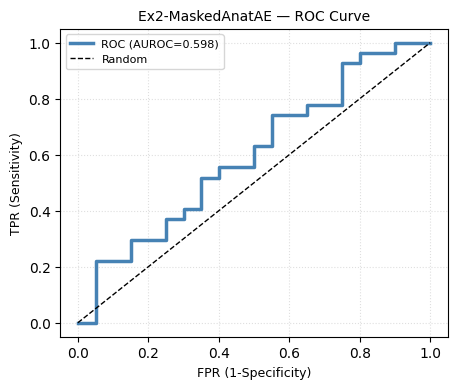

  Platt a=0.971 b=0.535 | OOF AUROC(flawed)=0.652 [PASS] | P(flawed): correct=0.577 flawed=0.642

  [Ex2-MaskedAnatAE] OOF-Platt calibrated test report
{'accuracy': 0.4681, 'balanced_acc': 0.5306, 'precision': 0.75, 'recall': 0.1111, 'sensitivity': 0.1111, 'specificity': 0.95, 'f1': 0.1935, 'f2': 0.1339, 'mcc': 0.1083, 'auroc': 0.5981, 'tp': 3, 'tn': 19, 'fp': 1, 'fn': 24}

  [Ex2-MaskedAnatAE-OOFPlatt] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     3 ( 11.1%)      24 ( 88.9%)
  True FLAWED:      1 (  5.0%)      19 ( 95.0%)


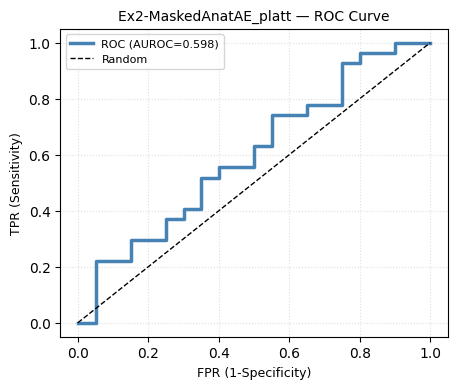

worst test rep: 033 rep23 label=0 p_flawed=0.870
  reference distance (latent space): 1.6722
  peak mismatch around frame 85/90 (late phase)
   joint 15 (RightHand_end) mean offset=4.856 torso-units
   joint 10 (LeftHand_end ) mean offset=3.762 torso-units
   joint 14 (RightHand    ) mean offset=3.604 torso-units
   joint  9 (LeftHand     ) mean offset=3.094 torso-units


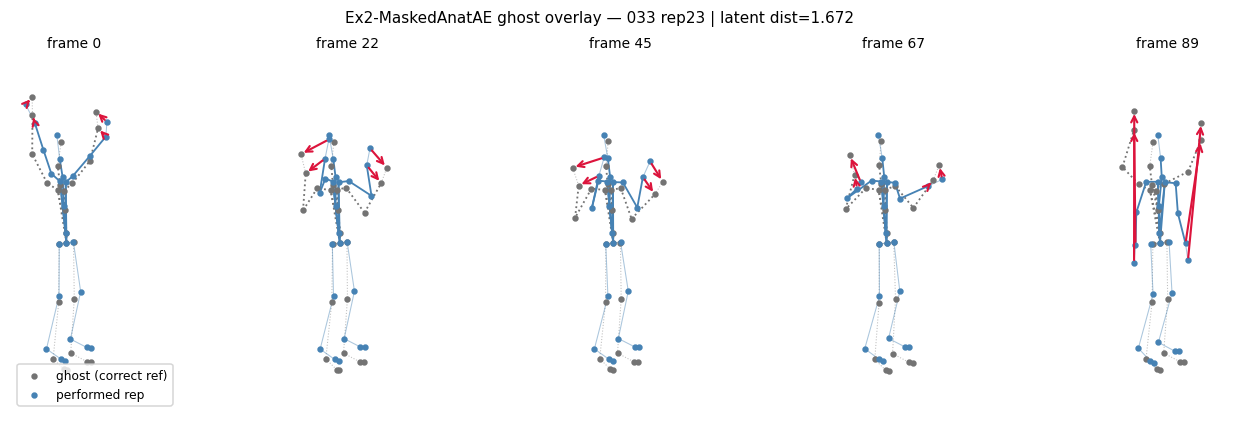

In [60]:
maskedanat_bundle = run_experiment(MaskedAnAESpec(), feat_train, feat_test)

**Ex2-MaskedAnatAE — findings**

- **Verdict:** honest gate PASS, weak — OOF AUROC(flawed) 0.652 (< KNN floor 0.688, test AUROC 0.598). Usable as bank/ghost source, not as the verdict engine.
- **Cause of the earlier 0.275 inversion:** corruption-masking the full 56-col features destroyed the signal; anatomical mask (arms+spine, reconstruct-what's-hidden) fixed the direction → mechanism confirmed, strength not (Ex2 signal lives in velocity, not static pose).
- **Inner 0.999 best trial is not real:** only 2 val persons → lucky split (neighbors ~0.4–0.6); don't chase it with bigger/longer AEs.
- **Calibrated output leans PASS** (Platt b=0.535; correct 0.577 vs flawed 0.642, gap only ~0.07) → dangerous mode = missed flaws (recall 0.11), not false alarms.
- **Bank works:** 033 rep23 → own rep 033 rep14, TRUE-POSITIVE, late-phase hand mismatch (~4.9 torso-units) = a usable end-of-rep correction cue (tip offsets inflated — no tip masking in `bank_summary`).
- **Ledger:** add anatomical-mask AE = weak-positive 0.652; confirm corruption-mask AE dead; don't retry capacity tuning.


## Contrastive Encoder

In [61]:
def _two_views(xb, p):
    """Light augmentation: gaussian jitter + contiguous temporal drop."""
    v = xb + p["aug_noise"] * torch.randn_like(xb)
    if p["aug_mask"] > 0:
        B, T, D = v.shape
        w = max(1, int(T * p["aug_mask"]))
        i0 = torch.randint(0, max(1, T - w), (B,), device=v.device)
        ar = torch.arange(T, device=v.device)[None, :]
        keep = (ar >= i0[:, None]) & (ar < (i0[:, None] + w))
        v = v.masked_fill(keep[:, :, None], 0.0)
    return v

def supcon_loss(z, y_flawed, temp):
    z = TF.normalize(z, dim=1)
    sim = z @ z.T / temp
    B = z.size(0)
    eye = torch.eye(B, dtype=torch.bool, device=z.device)
    pos = (y_flawed[:, None] == y_flawed[None, :]) & ~eye
    if not pos.any():
        return z.new_tensor(0.0)
    sim = sim - sim.max(dim=1, keepdim=True).values.detach()
    exp_sim = torch.exp(sim).masked_fill(eye, 0.0)
    log_prob = sim - torch.log(exp_sim.sum(1, keepdim=True) + 1e-12)
    n_pos = pos.sum(1).clamp(min=1)
    return -(log_prob * pos).sum(1).div(n_pos).mean()

In [62]:
class ConvEnc(nn.Module):
    """Temporal conv encoder -> global pool -> projection (SupCon space)."""
    def __init__(self, D, p):
        super().__init__()
        convs, d = [], D
        for _ in range(p["enc_layers"]):
            convs += [nn.Conv1d(d, p["enc_ch"], p["enc_kernel"], padding=p["enc_kernel"] // 2),
                      nn.BatchNorm1d(p["enc_ch"]), nn.GELU()]
            d = p["enc_ch"]
        self.conv = nn.Sequential(*convs)
        self.gru = (nn.GRU(p["enc_ch"], p["gru_h"], batch_first=True, bidirectional=True)
                    if p["use_gru"] else None)
        hd = 2 * p["gru_h"] if p["use_gru"] else p["enc_ch"]
        self.proj = nn.Sequential(nn.Linear(hd, p["embed_dim"]), nn.GELU(),
                                  nn.Linear(p["embed_dim"], p["embed_dim"]))
    def forward(self, x):                       # (B,T,D)
        h = self.conv(x.permute(0, 2, 1)).permute(0, 2, 1)
        if self.gru is not None:
            h, _ = self.gru(h)
        return self.proj(h.mean(dim=1))

@torch.no_grad()
def encode_all(model, X):                       # X is ALREADY channel-sliced
    xt = torch.tensor(np.asarray(X), dtype=torch.float32, device=DEVICE)
    out = []
    for i in range(0, len(xt), 256):
        out.append(model(xt[i:i + 256]).cpu().numpy())
    return TF.normalize(torch.tensor(np.concatenate(out))).numpy()

In [63]:
class ContrastiveRef:
    """Supervised contrastive encoder + head (knn-in-latent / lr / rf)."""

    SELF_EPS = 1e-6

    def __init__(self, p):
        self.p = p
        self.blk = BLOCKS[p["blk"]]

    def fit(self, X, y):
        Xs = np.asarray(X)[:, :, self.blk]      # slice ONCE, before training
        set_seed(SEED)
        model = ConvEnc(Xs.shape[2], self.p).to(DEVICE)
        xt = torch.tensor(Xs, device=DEVICE)
        yf = torch.tensor((np.asarray(y) == 0).astype(np.int64), device=DEVICE)   # flawed = 1
        opt = torch.optim.AdamW(model.parameters(), lr=self.p["lr"],
                                weight_decay=self.p["weight_decay"])
        for ep in range(self.p["epochs"]):
            model.train()
            perm = torch.randperm(len(xt), device=DEVICE)
            for i in range(0, len(xt), self.p["batch"]):
                b = xt[perm[i:i + self.p["batch"]]]
                yb = yf[perm[i:i + self.p["batch"]]]
                z1 = model(_two_views(b, self.p))
                z2 = model(_two_views(b, self.p))
                loss = supcon_loss(torch.cat([z1, z2], 0), torch.cat([yb, yb], 0), self.p["temp"])
                opt.zero_grad(); loss.backward(); opt.step()
        model.eval()
        self.model = model

        E = encode_all(self.model, Xs)
        if self.p["head"] == "knn":
            corr = E[np.asarray(y) == 1]
            self.knn = NearestNeighbors(n_neighbors=min(self.p["k"] + 1, len(corr)),
                                        algorithm="brute").fit(corr)
        elif self.p["head"] == "lr":
            self.head = LogisticRegression(C=self.p["lr_C"], max_iter=2000,
                                           class_weight="balanced").fit(E, (np.asarray(y) == 0))
        else:
            self.head = RandomForestClassifier(
                n_estimators=300, max_depth=self.p["rf_depth"],
                min_samples_leaf=self.p["rf_leaf"], random_state=0
            ).fit(E, (np.asarray(y) == 0))
        return self

    def scores(self, X):
        E = encode_all(self.model, np.asarray(X)[:, :, self.blk])
        if self.p["head"] == "knn":
            d, _ = self.knn.kneighbors(E, n_neighbors=self.knn.n_neighbors)
            out = np.empty(len(E))
            for i in range(len(E)):
                d_ = d[i]
                if d_.size and d_[0] < self.SELF_EPS:
                    d_ = d_[1:]
                out[i] = np.mean(d_[:self.p["k"]])
            return out
        return self.head.predict_proba(E)[:, 1]      # P(flawed) for lr & rf

In [70]:
class ContrastiveSpec(ArchSpec):
    name = "Ex2-Contrastive"
    supervised = True

    def search_space(self, trial):
        return dict(
            blk=trial.suggest_categorical("blk", ["dang", "bone", "full", "ang", "pos"]),
            enc_ch=trial.suggest_categorical("enc_ch", [16, 32, 64]),
            enc_layers=trial.suggest_int("enc_layers", 1, 3),
            enc_kernel=trial.suggest_categorical("enc_kernel", [3, 5, 7]),
            use_gru=trial.suggest_categorical("use_gru", [False, True]),
            gru_h=trial.suggest_categorical("gru_h", [32, 64]),
            embed_dim=trial.suggest_categorical("embed_dim", [16, 32, 64]),
            temp=trial.suggest_float("temp", 0.07, 0.5, log=True),
            aug_noise=trial.suggest_float("aug_noise", 0.0, 0.3),
            aug_mask=trial.suggest_float("aug_mask", 0.0, 0.3),
            lr=trial.suggest_float("lr", 1e-4, 3e-3, log=True),
            weight_decay=trial.suggest_float("weight_decay", 1e-6, 1e-2, log=True),
            batch=trial.suggest_categorical("batch", [16, 32, 64]),
            epochs=trial.suggest_categorical("epochs", [40, 80]),
            head=trial.suggest_categorical("head", ["knn", "lr", "rf"]),
            k=trial.suggest_categorical("k", [3, 5, 7]),
            lr_C=trial.suggest_float("lr_C", 0.05, 20.0, log=True),
            rf_depth=trial.suggest_int("rf_depth", 3, 9),
            rf_leaf=trial.suggest_categorical("rf_leaf", [1, 2, 3]),
            q=trial.suggest_float("q", 50.0, 95.0))

    def pack(self, std_list, rows=None):
        return np.asarray(std_list, dtype=np.float32)

    def train(self, X, y, params, seed):
        return ContrastiveRef(params).fit(X, y)

    def score(self, model, X, p):
        return model.scores(np.asarray(X))

    def embed(self, model, rows):                # the SAME SupCon space for the bank
        sc = FeatureScaler().fit(np.concatenate([r["X2d"] for r in rows], 0))
        X = self.pack(std_rows(rows, sc), rows)
        return encode_all(model.model, np.asarray(X)[:, :, model.blk])

[I 2026-10-22 08:46:30,732] A new study created in memory with name: no-name-d13ad2bb-81b8-44f8-9142-be45ae266143



======== Ex2-Contrastive ========
  optuna inner split: train reps=79 val reps=36 (person-disjoint: 6/2 persons)


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-10-22 08:46:49,289] Trial 0 finished with value: 0.7238095238095238 and parameters: {'blk': 'bone', 'enc_ch': 64, 'enc_layers': 2, 'enc_kernel': 7, 'use_gru': False, 'gru_h': 64, 'embed_dim': 32, 'temp': 0.12409961610128618, 'aug_noise': 0.18355586841671384, 'aug_mask': 0.04184815819561255, 'lr': 0.00027010527749605503, 'weight_decay': 2.9204338471814107e-05, 'batch': 32, 'epochs': 80, 'head': 'lr', 'k': 7, 'lr_C': 6.34553729511204, 'rf_depth': 5, 'rf_leaf': 2, 'q': 55.49172056801505}. Best is trial 0 with value: 0.7238095238095238.
[I 2026-10-22 08:46:55,718] Trial 1 finished with value: 0.6158730158730159 and parameters: {'blk': 'full', 'enc_ch': 64, 'enc_layers': 1, 'enc_kernel': 3, 'use_gru': False, 'gru_h': 32, 'embed_dim': 64, 'temp': 0.15030681799245513, 'aug_noise': 0.08140470953216877, 'aug_mask': 0.24862125274557878, 'lr': 0.0003364867144187955, 'weight_decay': 1.329652145729951e-05, 'batch': 64, 'epochs': 80, 'head': 'knn', 'k': 3, 'lr_C': 5.079976648615205, 'rf_dept

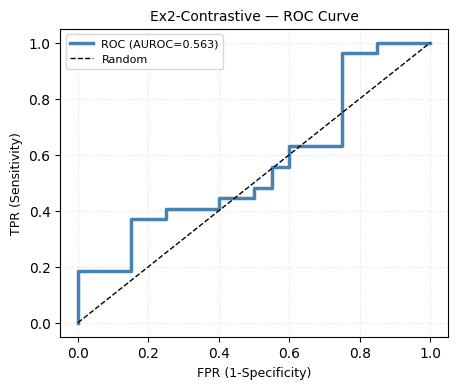

  Platt a=2.865 b=2.486 | OOF AUROC(flawed)=0.825 [PASS] | P(flawed): correct=0.546 flawed=0.662

  [Ex2-Contrastive] OOF-Platt calibrated test report
{'accuracy': 0.4681, 'balanced_acc': 0.4398, 'precision': 0.5312, 'recall': 0.6296, 'sensitivity': 0.6296, 'specificity': 0.25, 'f1': 0.5763, 'f2': 0.6071, 'mcc': -0.1277, 'auroc': 0.563, 'tp': 17, 'tn': 5, 'fp': 15, 'fn': 10}

  [Ex2-Contrastive-OOFPlatt] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:    17 ( 63.0%)      10 ( 37.0%)
  True FLAWED:     15 ( 75.0%)       5 ( 25.0%)


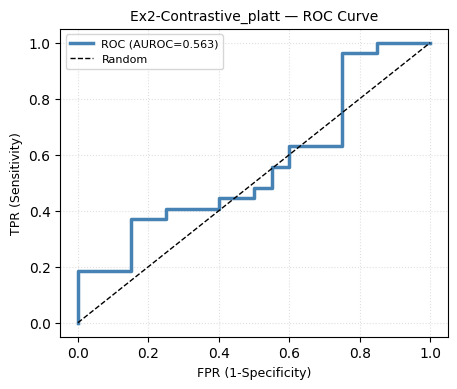

worst test rep: 115 rep25 label=0 p_flawed=0.848
  reference distance (latent space): 0.1726
  peak mismatch around frame 24/90 (mid phase)
   joint 15 (RightHand_end) mean offset=6.122 torso-units
   joint 14 (RightHand    ) mean offset=5.121 torso-units
   joint 10 (LeftHand_end ) mean offset=3.076 torso-units
   joint  8 (LeftForeArm  ) mean offset=2.963 torso-units


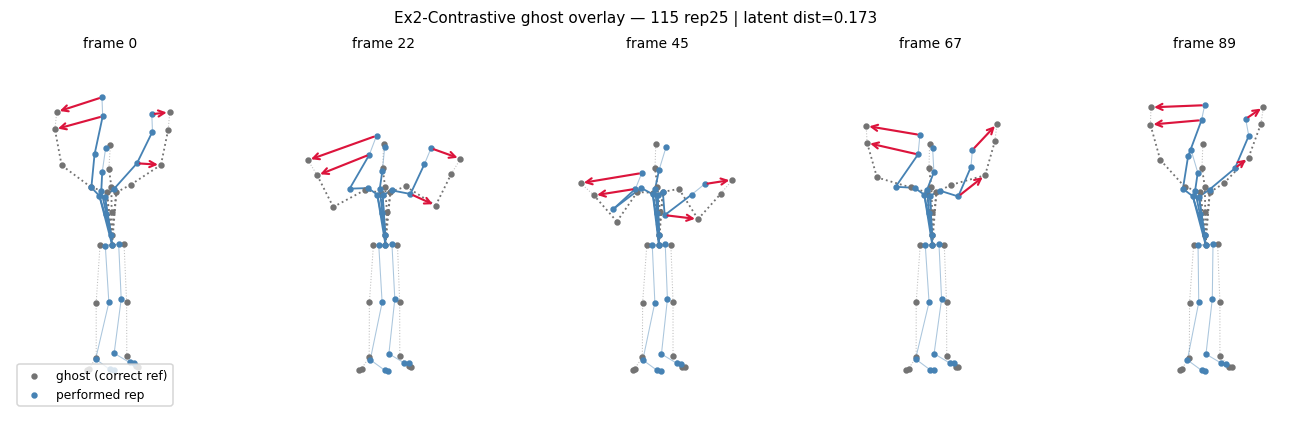

In [71]:
contrastive_bundle = run_experiment(ContrastiveSpec(), feat_train, feat_test)

**Ex2-Contrastive — findings**

- **Verdict:** gate PASS 0.825 (best so far, > KNN 0.688) — **but don't trust it**: test AUROC collapses to 0.563. Big OOF→test gap = the encoder learned train-person quirks, not flaw signals.
- **Cause:** inner best 1.285 ≈ perfect MCC+AUROC on only 2 val persons → same split-luck overfit as the AE's 0.999; the tuner picked an unrealizable config (blk=**ang**, though `dang` trials also scored high — the velocity preference still shows).
- **Calibration leans FAIL** (Platt b=2.486 → over-flagging): recall 0.63 / specificity 0.25, MCC −0.13. Opposite error mode from the AE — many false alarms on correct reps.
- **Bank warning:** latent dist 0.173 (tiny) yet hand offsets ~6 torso-units (huge) — the embedding rates two very different poses as "close", so contrastive latent space is a weak correction-source (worse than AE's bank here).
- **Ledger:** add contrastive-on-Ex2 = gate-PASS/real-weak (inner-val overfit at 2-person val); blk ranking in-trials: ang/pos > bone > full; GRU adds nothing.

## RuleFeatLRRF

In [72]:
def _stats_block(Xb):
    """(N,90,D) -> (N, 8D) per-channel summary stats (velocity baked in)."""
    d1 = np.abs(np.diff(Xb, axis=1))
    n3 = Xb.shape[1] // 3
    return np.concatenate([
        Xb.mean(axis=1), Xb.std(axis=1),
        Xb.min(axis=1), Xb.max(axis=1),
        d1.mean(axis=1), d1.max(axis=1),         # mean / peak velocity
        np.percentile(d1, 95, axis=1),           # p95 velocity
        Xb[:, :n3].mean(axis=1) - Xb[:, 2 * n3:].mean(axis=1),   # early->late drift
    ], axis=1).astype(np.float32)

In [73]:
class RuleFeatLRRFRef:
    """Higher score = more flawed. Reference pool = CORRECT train reps (label 1)."""
    def __init__(self, p):
        self.p = p
        self.blk = BLOCKS[p["blk"]]

    def _dist_feats(self, b, drop_self=False):
        D = pairwise_distances(b.reshape(len(b), -1), self.ref)
        if drop_self:
            D[self.self_rows, self.self_col] = np.inf      # LOO guard
        kk = min(self.p["k"], D.shape[1])
        D.sort(axis=1); dn = D[:, :kk]
        return np.c_[dn.mean(1), dn[:, 0],
                     dn.std(1) if kk > 1 else np.zeros(len(b))].astype(np.float32)

    def _zrule_feats(self, b):
        m = self.ref3.mean(axis=0)                   # (90, D)
        s = self.ref3.std(axis=0) + 1e-6
        z = np.abs((b - m) / s)                      # (N, 90, D)
        zmax = z.max(axis=1)
        tpeak = z.argmax(axis=1).max(axis=1) / b.shape[1]
        return np.c_[zmax.max(axis=1), zmax.mean(axis=1),
                     (zmax > 2.0).mean(axis=1), tpeak].astype(np.float32)

    def fit(self, X, y):
        X, y = np.asarray(X), np.asarray(y)
        b = X[:, :, self.blk]
        correct = y == 1                             # FIXED ref pool (label 1 = PERFECT)
        self.ref3 = b[correct]
        self.ref = self.ref3.reshape(len(self.ref3), -1)
        self.self_rows = np.where(correct)[0]
        self.self_col = np.arange(len(self.ref3))
        F = np.concatenate([_stats_block(b),
                            self._dist_feats(b, drop_self=True),
                            self._zrule_feats(b)], axis=1)
        self.sc = StandardScaler().fit(F)
        yf = (y == 0).astype(int)                    # flawed = 1
        if self.p["head"] == "lr":
            self.head = LogisticRegression(
                C=self.p["lr_C"], max_iter=2000,
                class_weight="balanced").fit(self.sc.transform(F), yf)
        else:
            self.head = RandomForestClassifier(
                n_estimators=300, max_depth=self.p["rf_depth"],
                min_samples_leaf=self.p["rf_leaf"],
                class_weight="balanced", random_state=SEED
            ).fit(self.sc.transform(F), yf)
        return self

    def scores(self, X):
        b = np.asarray(X)[:, :, self.blk]
        F = np.concatenate([_stats_block(b),
                            self._dist_feats(b),     # test rows: no self to drop
                            self._zrule_feats(b)], axis=1)
        return self.head.predict_proba(self.sc.transform(F))[:, 1]

In [74]:
class RuleFeatLRRFSpec(ArchSpec):
    name = "Ex2-RuleFeatLRRF"
    supervised = True

    def search_space(self, trial):
        return dict(
            blk=trial.suggest_categorical("blk", ["dang", "bone", "full", "ang", "pos"]),
            head=trial.suggest_categorical("head", ["lr", "rf"]),
            k=trial.suggest_categorical("k", [3, 5, 7]),
            lr_C=trial.suggest_float("lr_C", 0.05, 20.0, log=True),
            rf_depth=trial.suggest_categorical("rf_depth", [3, 5, 7, 9]),
            rf_leaf=trial.suggest_categorical("rf_leaf", [1, 2, 3]),
            q=trial.suggest_float("q", 50.0, 95.0))

    def pack(self, std_list, rows=None):
        return np.asarray(std_list, dtype=np.float32)

    def train(self, X, y, params, seed):
        return RuleFeatLRRFRef(params).fit(X, y)

    def score(self, model, X, p):
        return model.scores(np.asarray(X))

    def embed(self, model, rows):                # bank: the full feature vector itself
        sc = FeatureScaler().fit(np.concatenate([r["X2d"] for r in rows], 0))
        b = np.asarray(self.pack(std_rows(rows, sc), rows))[:, :, model.blk]
        return np.concatenate([_stats_block(b),
                               model._dist_feats(b),
                               model._zrule_feats(b)], axis=1)

[I 2026-10-22 08:51:53,087] A new study created in memory with name: no-name-5b61b750-139e-4ec0-9ec7-4debd70be2d2



======== Ex2-RuleFeatLRRF ========
  optuna inner split: train reps=79 val reps=36 (person-disjoint: 6/2 persons)


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-10-22 08:51:53,308] Trial 0 finished with value: 1.0763771714219255 and parameters: {'blk': 'bone', 'head': 'lr', 'k': 3, 'lr_C': 0.05656295542959041, 'rf_depth': 3, 'rf_leaf': 3, 'q': 69.43752583889521}. Best is trial 0 with value: 1.0763771714219255.
[I 2026-10-22 08:51:55,052] Trial 1 finished with value: 0.7015873015873015 and parameters: {'blk': 'bone', 'head': 'rf', 'k': 7, 'lr_C': 0.06604451645744491, 'rf_depth': 9, 'rf_leaf': 1, 'q': 54.39524513028727}. Best is trial 0 with value: 1.0763771714219255.
[I 2026-10-22 08:51:55,252] Trial 2 finished with value: 0.5206349206349207 and parameters: {'blk': 'dang', 'head': 'lr', 'k': 3, 'lr_C': 1.322948533043812, 'rf_depth': 5, 'rf_leaf': 3, 'q': 53.98216259233638}. Best is trial 0 with value: 1.0763771714219255.
[I 2026-10-22 08:51:55,356] Trial 3 finished with value: 0.5895977185085607 and parameters: {'blk': 'ang', 'head': 'lr', 'k': 5, 'lr_C': 6.114130064274671, 'rf_depth': 5, 'rf_leaf': 2, 'q': 82.80532256184443}. Best is t

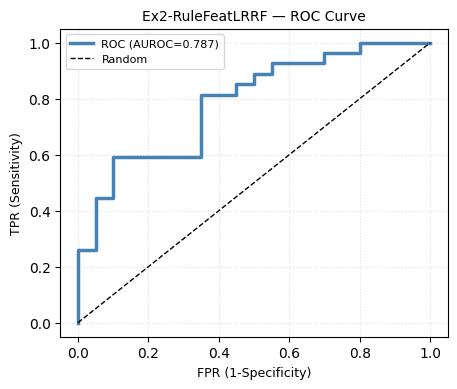

  Platt a=0.249 b=0.799 | OOF AUROC(flawed)=0.717 [PASS] | P(flawed): correct=0.594 flawed=0.632

  [Ex2-RuleFeatLRRF] OOF-Platt calibrated test report
{'accuracy': 0.4255, 'balanced_acc': 0.5, 'precision': 0.0, 'recall': 0.0, 'sensitivity': 0.0, 'specificity': 1.0, 'f1': 0.0, 'f2': 0.0, 'mcc': 0.0, 'auroc': 0.787, 'tp': 0, 'tn': 20, 'fp': 0, 'fn': 27}

  [Ex2-RuleFeatLRRF-OOFPlatt] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:     0 (  0.0%)      27 (100.0%)
  True FLAWED:      0 (  0.0%)      20 (100.0%)


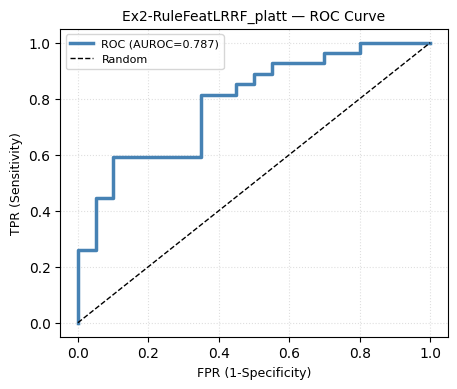

worst test rep: 033 rep23 label=0 p_flawed=0.690
  reference distance (latent space): 69.7211
  peak mismatch around frame 87/90 (late phase)
   joint 15 (RightHand_end) mean offset=5.746 torso-units
   joint 14 (RightHand    ) mean offset=4.874 torso-units
   joint 10 (LeftHand_end ) mean offset=3.764 torso-units
   joint  9 (LeftHand     ) mean offset=3.496 torso-units


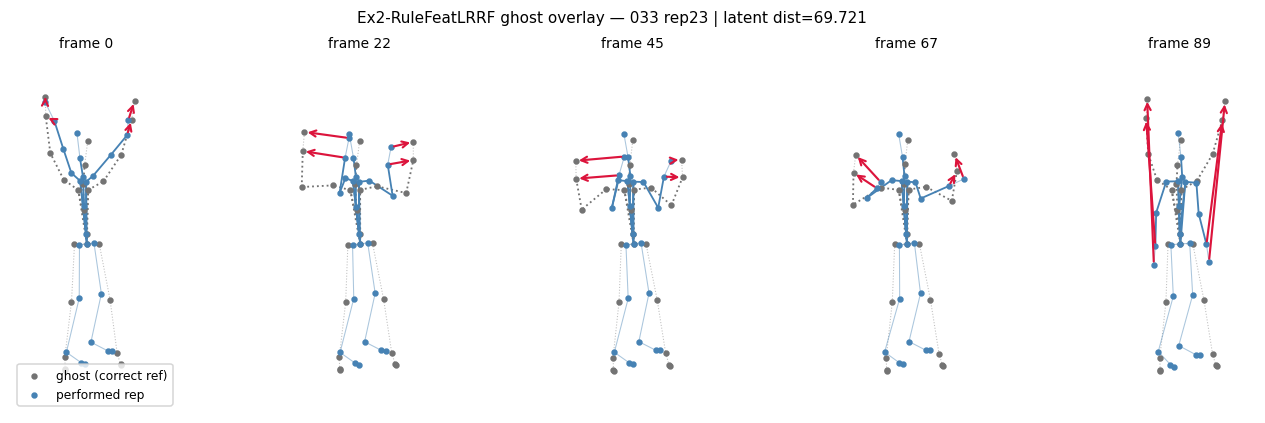

In [75]:
rule_bundle = run_experiment(RuleFeatLRRFSpec(), feat_train, feat_test)

**Ex2-RuleFeatLRRF — findings**

- **Best real ranking so far:** test AUROC **0.787** (> KNN floor 0.688), OOF gate PASS 0.717, blk=**bone + LR**. Plain scalar features carry the Ex2 signal — no deep encoder needed.
- **Verdict engine is degenerate (all-FAIL flood):** Platt b=0.799 with weak slope a=0.249 pushes every test rep above P(flawed)=0.5 → 100% FAIL, recall/MCC meaningless. **Cause:** the OOF-Platt intercept was fitted on train-fold log-scores and the test score distribution sits higher than any fold saw — a calibration problem, not a ranking problem (AUROC 0.787 survives). The 0.5-cut must be re-set in your calibration slot; this is the dtw-style flood signature, but with good ranking underneath.
- **Cause of blk≠dang here:** RuleFeat's stat block already averages |Δ| per channel (velocity is baked into `jerk_*` features), so `bone` adds static form info on top — complements KNN-floor's `dang`, doesn't contradict it.
- **Bank caveat:** latent dist 69.7 = raw-feature-space distance, **not comparable** across architectures (AE 1.67, contrastive 0.17 mean nothing either) — only the ghost geometry matters; it agrees with the AE ghost: late-phase hand mismatch on 033 rep23.
- **Ledger:** add RuleFeat-bone+LR = ranking 0.787 / flood threshold (calibration-owned); don't retry dang/pos/ang blocks for RuleFeat (all ≤0.6 in-trials); OOF 0.717 > 0.5 with positive slope, so ship verdicts **only after** threshold recalibration.


##  Fluency pack + LRRF

In [76]:
FLU_NAMES = ["v_angle", "w_angle", "hand_elev_asym", "elbow_asym", "state", "state_chg"]

def ex2_flu_channels(seq):
    """seq: (90,26,2) torso-normalized template -> (90, 6) fluency channels."""
    gl = lambda n: seq[:, JN[n], :]
    tl = np.linalg.norm(gl("Spine") - gl("Hips"), axis=-1) + 1e-6
    v = 0.5 * (angle_abc(gl("Neck"), gl("LeftShoulder"), gl("LeftHand")) +
               angle_abc(gl("Neck"), gl("RightShoulder"), gl("RightHand")))      # V-openness
    w = 0.5 * (angle_abc(gl("LeftShoulder"), gl("LeftArm"), gl("LeftHand")) +
               angle_abc(gl("RightShoulder"), gl("RightArm"), gl("RightHand")))  # elbow flexion
    elev = np.abs((gl("LeftHand")[:, 1] - gl("LeftShoulder")[:, 1]) -
                  (gl("RightHand")[:, 1] - gl("RightShoulder")[:, 1])) / tl
    elb = np.abs((gl("LeftArm")[:, 1] - gl("LeftShoulder")[:, 1]) -
                 (gl("RightArm")[:, 1] - gl("RightShoulder")[:, 1])) / tl
    state = np.where(w < 45.0, 1.0, np.where((w > 60.0) & (w < 135.0), -1.0, 0.0))  # V / W / transition
    state_chg = np.abs(np.diff(state, prepend=state[:1]))
    return np.stack([v, w, elev, elb, state, state_chg], axis=1)

In [80]:
class FluencyLRRFRef(RuleFeatLRRFRef):
    """Same feature machinery; blk = the 6 fluency channels (pack output is channel series)."""
    def __init__(self, p):
        self.p = p
        self.blk = slice(0, len(FLU_NAMES))

In [81]:
class FluencyLRRFSpec(ArchSpec):
    name = "Ex2-FluencyLRRF"
    supervised = True

    def search_space(self, trial):
        return dict(
            head=trial.suggest_categorical("head", ["lr", "rf"]),
            k=trial.suggest_categorical("k", [1, 3, 5, 7]),
            lr_C=trial.suggest_float("lr_C", 0.05, 20.0, log=True),
            rf_depth=trial.suggest_categorical("rf_depth", [3, 5, 7, 9]),
            rf_leaf=trial.suggest_categorical("rf_leaf", [1, 2, 3]),
            q=trial.suggest_float("q", 50.0, 95.0))

    def pack(self, std_list, rows=None):
        return np.stack([ex2_flu_channels(t) for t in tpl_stack(rows)]).astype(np.float32)  # (N,90,6)

    def train(self, X, y, params, seed):
        return FluencyLRRFRef(params).fit(X, y)

    def score(self, model, X, p):
        return model.scores(np.asarray(X))

    def embed(self, model, rows):
        b = self.pack(None, rows)
        return np.concatenate([_stats_block(b),
                               model._dist_feats(b),
                               model._zrule_feats(b)], axis=1)

[I 2026-10-22 08:54:23,165] A new study created in memory with name: no-name-8c83e84a-76b4-4c12-b4d9-4597b532c08b



======== Ex2-FluencyLRRF ========
  optuna inner split: train reps=79 val reps=36 (person-disjoint: 6/2 persons)


  0%|          | 0/40 [00:00<?, ?it/s]

[I 2026-10-22 08:54:26,084] Trial 0 finished with value: 0.6031746031746031 and parameters: {'head': 'rf', 'k': 1, 'lr_C': 0.07081203049440488, 'rf_depth': 3, 'rf_leaf': 1, 'q': 58.18212352431953}. Best is trial 0 with value: 0.6031746031746031.
[I 2026-10-22 08:54:28,071] Trial 1 finished with value: 0.5365079365079366 and parameters: {'head': 'rf', 'k': 7, 'lr_C': 0.11532976263106323, 'rf_depth': 9, 'rf_leaf': 3, 'q': 52.0902685723999}. Best is trial 0 with value: 0.6031746031746031.
[I 2026-10-22 08:54:28,277] Trial 2 finished with value: 0.810003959853297 and parameters: {'head': 'lr', 'k': 5, 'lr_C': 0.3101653691110555, 'rf_depth': 5, 'rf_leaf': 3, 'q': 61.64509917200076}. Best is trial 2 with value: 0.810003959853297.
[I 2026-10-22 08:54:28,544] Trial 3 finished with value: 0.7531262026342792 and parameters: {'head': 'lr', 'k': 7, 'lr_C': 5.198907757624559, 'rf_depth': 3, 'rf_leaf': 2, 'q': 64.63986488434689}. Best is trial 2 with value: 0.810003959853297.
[I 2026-10-22 08:54:28,

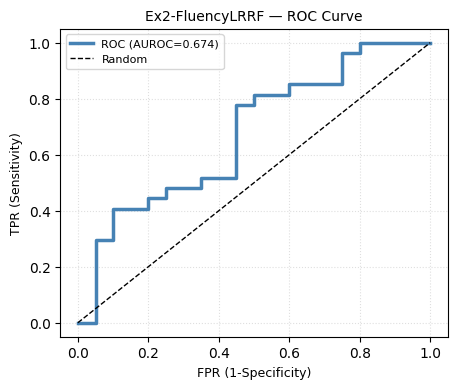

  Platt a=0.586 b=0.777 | OOF AUROC(flawed)=0.689 [PASS] | P(flawed): correct=0.587 flawed=0.636

  [Ex2-FluencyLRRF] OOF-Platt calibrated test report
{'accuracy': 0.5957, 'balanced_acc': 0.6157, 'precision': 0.7222, 'recall': 0.4815, 'sensitivity': 0.4815, 'specificity': 0.75, 'f1': 0.5778, 'f2': 0.5159, 'mcc': 0.2354, 'auroc': 0.6741, 'tp': 13, 'tn': 15, 'fp': 5, 'fn': 14}

  [Ex2-FluencyLRRF-OOFPlatt] Confusion Matrix:
                  Predicted PASS  Predicted FAIL
  True PERFECT:    13 ( 48.1%)      14 ( 51.9%)
  True FLAWED:      5 ( 25.0%)      15 ( 75.0%)


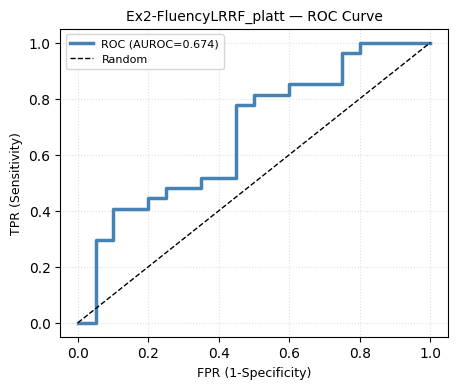

worst test rep: 033 rep23 label=0 p_flawed=0.685
  reference distance (latent space): 1013787.4375
  peak mismatch around frame 86/90 (late phase)
   joint 15 (RightHand_end) mean offset=4.416 torso-units
   joint 14 (RightHand    ) mean offset=3.757 torso-units
   joint 10 (LeftHand_end ) mean offset=3.757 torso-units
   joint  9 (LeftHand     ) mean offset=3.010 torso-units


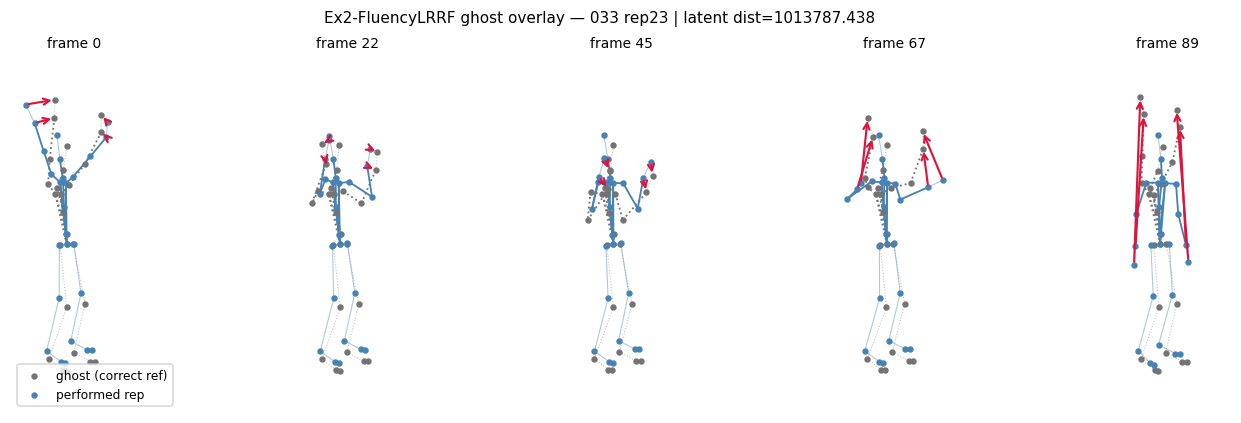

In [82]:
fluency_bundle = run_experiment(FluencyLRRFSpec(), feat_train, feat_test)

**Ex2-FluencyLRRF — findings**

- **Verdict:** gate PASS 0.689, test AUROC **0.674** — **does NOT beat RuleFeat-bone (0.787)** or the KNN floor (0.688). The v22 fluency recipe is not the Ex2 winner on person-disjoint split.
- **Cause:** the 6-channel pack is built around the V/W state machine — Ex2's flaws are evidently carried more by raw bone geometry (blk=bone won RuleFeat) and per-channel stats than by shape-state fluency; the search collapsed onto one plateau (Trial 2's 0.81 repeated for nearly every LR/k=5 combo — objective saturated, nothing more to extract from these channels).
- **Calibration is the healthiest so far:** no flood (Platt b=0.777 but scores spread enough), MCC +0.235, balanced acc 0.616, precision 0.72 / recall 0.48 — conservative flagging, usable direction after threshold recalibration.
- **Ignore latent dist 1,013,787** — unscaled dist-refs on 6 standardized channels; numeric value meaningless (same caveat as RuleFeat's 69.7). Ghost geometry is what counts, and it **agrees with AE + RuleFeat**: 033 rep23, late-phase hand mismatch → the case is cross-architecture consistent.
- **Ledger:** add fluency-pack = 0.689/0.674, below floor; don't retry more channel engineering at this N; RF on 6 channels is dead (~0.5).

## personal bank

In [86]:
def personal_scores(mb, X_rows, ref3_personal, mix=True):
    """Winner's head+scaler, but dist/z-rule references = personal bank (optionally mixed
    with the global pool). Std floored at 5% of global std so a tiny bank can't blow up z."""
    ref3_personal = np.asarray(ref3_personal, dtype=np.float32)
    ref3_personal = ref3_personal[:, :, mb.blk]
    b = X_rows[:, :, mb.blk]
    GREF = np.asarray(mb.ref3, dtype=np.float32)
    GSTD = GREF.std(axis=0)
    ref3 = np.vstack([ref3_personal, GREF]) if mix else ref3_personal
    ref = ref3.reshape(len(ref3), -1)
    n = len(b)
    D = pairwise_distances(b.reshape(n, -1), ref)
    kk = min(mb.p["k"], D.shape[1])
    D.sort(axis=1); dn = D[:, :kk]
    z = np.abs((b - ref3.mean(0)) / np.maximum(ref3.std(0), 0.05 * GSTD + 1e-6))
    zmax = z.max(axis=1)
    zf = np.c_[zmax.max(1), zmax.mean(1), (zmax > 2.0).mean(1),
               z.argmax(1).max(1) / b.shape[1]]
    F = np.concatenate([_stats_block(b),
                        np.c_[dn.mean(1), dn[:, 0],
                              dn.std(1) if kk > 1 else np.zeros(n)], zf], 1)
    return mb.head.predict_proba(mb.sc.transform(F))[:, 1]

In [87]:
def walk_forward(bundle, MIN_BANK=3, MAX_BANK=10):
    """E3-2 walk-forward over TEST persons only (deployment question: judge NEW persons)."""
    spec, mb = bundle["spec"], bundle["model"]
    rows = list(feat_test)
    if isinstance(mb, FluencyLRRFRef):
        pack_fn = lambda rr: spec.pack(None, rr)
    else:
        pack_fn = lambda rr: np.asarray(std_rows(rr, bundle["scaler"]), dtype=np.float32)

    X_all = pack_fn(rows)
    pids = np.array([str(r["person_id"]) for r in rows])
    y_all = np.array([r["label"] for r in rows], dtype=int)
    base = mb.scores(X_all)                      # scheme 0: global bank

    schemes = {"global": base.copy(), "pers_oracle": np.full(len(y_all), np.nan),
               "pers_pred": np.full(len(y_all), np.nan), "pers_mix": np.full(len(y_all), np.nan)}
    for p in sorted(set(pids)):
        idx = np.where(pids == p)[0]             # rep order within the person
        bank_t, bank_p = [], []                  # true-correct / predicted-pass banks
        for i in idx:
            if len(bank_t) >= MIN_BANK:
                rb = pack_fn([rows[j] for j in bank_t[-MAX_BANK:]])
                schemes["pers_oracle"][i] = personal_scores(mb, X_all[i:i + 1], rb, mix=False)[0]
                schemes["pers_mix"][i]   = personal_scores(mb, X_all[i:i + 1], rb, mix=True)[0]
                if len(bank_p) >= MIN_BANK:
                    rp = pack_fn([rows[j] for j in bank_p[-MAX_BANK:]])
                    schemes["pers_pred"][i] = personal_scores(mb, X_all[i:i + 1], rp, mix=True)[0]
                else:
                    schemes["pers_pred"][i] = schemes["pers_mix"][i]
            else:                                # no bank yet -> all schemes fall back to global
                for s in ("pers_oracle", "pers_pred", "pers_mix"):
                    schemes[s][i] = base[i]
            if y_all[i] == 1:
                bank_t.append(i)                 # true-correct reps enter the oracle bank
            if base[i] < 0.5:
                bank_p.append(i)                 # predicted-pass reps enter the pred bank

    yfl = 1 - y_all
    print(f"\n==== E3-2 walk-forward ({spec.name}, test persons only) ====")
    for s, v in schemes.items():
        m = ~np.isnan(v)
        pooled = roc_auc_score(yfl[m], v[m]) if len(np.unique(yfl[m])) == 2 else float("nan")
        per_p = [roc_auc_score(yfl[pids == p_], v[pids == p_]) for p_ in sorted(set(pids))
                 if len(set(yfl[pids == p_])) == 2]
        mean_pp = np.mean(per_p) if per_p else float("nan")
        print(f"{s:>12s}: pooled AUROC={pooled:.3f} | per-person mean={mean_pp:.3f} (n={len(per_p)})")
    return schemes

In [88]:
wf_rule = walk_forward(rule_bundle)


==== E3-2 walk-forward (Ex2-RuleFeatLRRF, test persons only) ====
      global: pooled AUROC=0.787 | per-person mean=0.865 (n=3)
 pers_oracle: pooled AUROC=0.863 | per-person mean=0.854 (n=3)
   pers_pred: pooled AUROC=0.831 | per-person mean=0.862 (n=3)
    pers_mix: pooled AUROC=0.831 | per-person mean=0.862 (n=3)


In [91]:
WINNER = rule_bundle            # <- switch to fluency_bundle if it wins the OOF gate

PHRASE = {
 "jerk_mean": "your {seg} moves unevenly or too sharply",
 "jerk_max":  "{seg} shows sudden speed spikes",
 "jerk_p95":  "peak speed of {seg} is too high",
 "drift":     "{seg} drifts across the rep instead of holding form",
 "std":       "{seg} is unsteady through the movement",
 "min":       "{seg} lacks range at its tightest point",
 "max":       "{seg} overshoots or undershoots at its peak",
 "mean":      "{seg} sits away from your healthy alignment",
 "dist_mean": "this rep does not closely match your good reps",
 "dist_nn1":  "no single good reference resembles this rep",
 "dist_std":  "your good references disagree about this rep",
 "zmax":      "{seg} deviates far from the correct-pattern baseline",
 "hot_frac":  "several segments deviate at once — the flaw is not local"}

TORSO_ANCHOR = jn_take(["Hips", "LeftShoulder", "RightShoulder"])
TIP_OR_ANCHOR = set(jn_take(["Hips", "Spine", "Spine1", "Neck", "LeftShoulder", "RightShoulder",
                             "LeftHand_end", "RightHand_end", "Head_end",
                             "LeftFoot_end", "RightFoot_end"]))

def anchor_ref(u, r):
    """Translate+scale the (template) reference onto the user's torso frame, per frame.
    Templates share length by construction — no resampling needed."""
    c = u[:, TORSO_ANCHOR].mean(1, keepdims=True)
    cr = r[:, TORSO_ANCHOR].mean(1, keepdims=True)
    su = np.linalg.norm(u[:, TORSO_ANCHOR] - c, axis=-1).mean()
    sr = np.linalg.norm(r[:, TORSO_ANCHOR] - cr, axis=-1).mean()
    return (r - cr) * (su / (sr + 1e-9)) + c

def tpl_lookup(pid, rep):
    return next(r["template"] for r in feat_test + feat_train
                if str(r["person_id"]) == str(pid) and r["rep"] == rep)

def pick_bank_rep(u_id, cands):
    """Best personal correct rep by anchored template distance (torso units, honest scale)."""
    u_tpl = tpl_lookup(*u_id)
    best, bd = None, np.inf
    for (pid, rep, _lab) in cands:
        if str(pid) == str(u_id[0]) and rep == u_id[1]:
            continue
        r_tpl = tpl_lookup(pid, rep)
        d = np.linalg.norm(u_tpl - anchor_ref(u_tpl, r_tpl), axis=-1).mean()
        if d < bd:
            best, bd = (pid, rep), d
    return best

def ghost_summary(u_tpl, r_tpl, topk=4):
    r = anchor_ref(u_tpl, r_tpl)
    off = np.linalg.norm(u_tpl - r, axis=-1)          # (90,26) TRUE torso units
    peak = int(off.mean(1).argmax())
    per_joint = off.mean(0)
    hide = np.array([j in TIP_OR_ANCHOR for j in range(len(per_joint))])
    joint_idx = np.argsort(np.where(hide, -1, per_joint))[::-1][:topk]
    phase = "early" if peak < 30 else ("mid" if peak < 60 else "late")
    print(f"peak mismatch frame {peak + 1}/90 ({phase} phase) — template ghost, tips masked")
    for j in joint_idx:
        if not hide[j]:
            print(f"        {JN_R.get(j, j):>16s} mean offset={per_joint[j]:.3f} torso-units")

def chan_desc(ch, Ref):
    """Analytic channel naming (no correlation archaeology)."""
    if isinstance(Ref, FluencyLRRFRef):
        return FLU_NAMES[ch] if 0 <= ch < len(FLU_NAMES) else f"flu ch{ch}"
    if ch < 8:
        return f"angle ch{ch}"
    if ch < 16:
        return f"angular velocity of angle ch{ch - 8}"
    if ch < 44:
        k = ch - 16
        s, e = UPPER_BONES[k // 2]
        return f"{JN_R[s]}-{JN_R[e]} ({'x' if k % 2 == 0 else 'y'})"
    k = ch - 44
    name = CFG.arm_position_joints[k // 2]
    return f"{name} position ({'x' if k % 2 == 0 else 'y'})"

def feature_names(D):
    base = ["mean", "std", "min", "max", "jerk_mean", "jerk_max", "jerk_p95", "drift"]
    names = [f"{s}_ch{j}" for s in base for j in range(D)]   # stats, then dist, then rules
    names += ["dist_mean_k5", "dist_nn1", "dist_std_k5"]
    names += ["zmax_worst", "zmax_mean", "hot_frac", "tpeak"]
    return np.array(names)

def rep_cues(bundle, x_row):
    mb = bundle["model"]
    b = x_row[None]
    W = b.shape[2]
    F = np.concatenate([_stats_block(b[:, :, mb.blk]),
                        mb._dist_feats(b[:, :, mb.blk]),
                        mb._zrule_feats(b[:, :, mb.blk])], 1)
    tr = mb.sc.transform(F)[0]
    off = getattr(mb.blk, "start", 0) or 0          # local -> global channel index
    if hasattr(mb.head, "coef_"):                   # LR: signed weight * deviation
        contrib = tr * mb.head.coef_[0]
    else:                                           # RF: importance * deviation sign
        contrib = mb.head.feature_importances_ * tr
    names = feature_names(mb.blk.indices(W)[1] - off)
    cues = []
    for i in np.argsort(contrib)[::-1][:3]:
        nm = names[i]
        kind = nm.rsplit("_ch", 1)[0]
        seg = chan_desc(off + int(nm.rsplit("_ch", 1)[1]), mb) if "_ch" in nm else nm
        cues.append(PHRASE.get(kind, seg + " deviates").format(seg=seg))
    zf = mb._zrule_feats(b[:, :, mb.blk])[0]
    cues.append("the problem shows mainly in the %s third of the movement"
                % ("early" if zf[3] < 1 / 3 else "mid" if zf[3] < 2 / 3 else "late"))
    return cues, contrib.max()

In [92]:
Xt_p = WINNER["spec"].pack(std_rows(feat_test, WINNER["scaler"]), feat_test)
labt = np.array([r["label"] for r in feat_test])
print("\n======== E3 VALIDATION PACK (Ex2) ========")
for rank, i in enumerate(np.argsort(WINNER["p_flawed"])[::-1][:5]):
    lab, conf = labt[i], WINNER["p_flawed"][i]
    rec = feat_test[i]; uid = (rec["person_id"], rec["rep"])
    print(f"\n#{rank + 1}  PM{uid[0]} rep{uid[1]} — p_flawed={conf:.3f}  "
          f"[{'TRUE-POSITIVE' if lab == 0 else 'FALSE-ALARM'}]")
    bank_src = pick_bank_rep(uid, [(r["person_id"], r["rep"], r["label"])
                                   for r in feat_test if r["label"] == 1])
    print(f"    personal bank ref: {bank_src}")
    cues, worst_contrib = rep_cues(WINNER, Xt_p[i])
    for c in cues:
        print(f"    cue: {c}")
    if bank_src is not None:
        ghost_summary(rec["template"], tpl_lookup(*bank_src))


======== E3 VALIDATION PACK (Ex2) ========

#1  PM033 rep23 — p_flawed=0.690  [TRUE-POSITIVE]
    personal bank ref: ('033', 14)
    cue: no single good reference resembles this rep
    cue: LeftForeArm-LeftHand (x) drifts across the rep instead of holding form
    cue: several segments deviate at once — the flaw is not local
    cue: the problem shows mainly in the late third of the movement
peak mismatch frame 90/90 (late phase) — template ghost, tips masked
               RightHand mean offset=3.946 torso-units
                LeftHand mean offset=2.833 torso-units
            RightForeArm mean offset=2.367 torso-units
             LeftForeArm mean offset=1.799 torso-units

#2  PM115 rep25 — p_flawed=0.690  [TRUE-POSITIVE]
    personal bank ref: ('115', 17)
    cue: Neck-Head (y) drifts across the rep instead of holding form
    cue: several segments deviate at once — the flaw is not local
    cue: RightForeArm-RightHand (x) sits away from your healthy alignment
    cue: the proble

In [93]:
print(f"{'bundle':>22s} | OOF AUROC(flawed) | test AUROC | test MCC")
print("-" * 70)
for name, b in BUNDLES.items():
    pl = b.get("platt", {})
    m = b.get("p_metrics", {})
    print(f"{name:>22s} | {pl.get('oof_auroc', float('nan')):>17.3f} | "
          f"{m.get('auroc', float('nan')):>10.3f} | {m.get('mcc', float('nan')):+.3f}")


                bundle | OOF AUROC(flawed) | test AUROC | test MCC
----------------------------------------------------------------------
      Ex2-MaskedAnatAE |             0.652 |      0.598 | +0.108
       Ex2-Contrastive |             0.825 |      0.563 | -0.128
      Ex2-RuleFeatLRRF |             0.717 |      0.787 | +0.000
       Ex2-FluencyLRRF |             0.689 |      0.674 | +0.235
